# Titanic Survival Prediction 🚢
**Problem:** Given a passenger's class, sex, age, family size and fare, predict whether they survived the Titanic disaster.
**Type:** Binary classification · **Dataset:** 891 passengers (the classic Titanic dataset)

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np

URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Clean and prepare the features
- Fill missing ages with the median age
- Convert `sex` and `embarked` into numbers (one-hot encoding)
- Drop columns that do not help prediction (names/text columns and free-text fields)

In [2]:
data = df.copy()
data["age"] = data["age"].fillna(data["age"].median())
data["embarked"] = data["embarked"].fillna(data["embarked"].mode()[0])
data["fare"] = data["fare"].fillna(data["fare"].median())

features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X = pd.get_dummies(data[features], columns=["sex", "embarked"], drop_first=True)
y = data["survived"]
print(X.shape)
X.head()

(891, 8)


,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S
0,3,22.0,1,0,7.2500,True,False,True
1,1,38.0,1,0,71.2833,False,False,False
2,3,26.0,0,0,7.9250,False,False,True
3,1,35.0,1,0,53.1000,False,False,True
4,3,35.0,0,0,8.0500,True,False,True


## 3. Train two models and compare them

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)
acc_lr = accuracy_score(y_test, log_reg.predict(X_test))

forest = RandomForestClassifier(n_estimators=300, random_state=42)
forest.fit(X_train, y_train)
acc_rf = accuracy_score(y_test, forest.predict(X_test))

print(f"Logistic Regression accuracy: {acc_lr:.3f}")
print(f"Random Forest accuracy:       {acc_rf:.3f}")

Logistic Regression accuracy: 0.804
Random Forest accuracy:       0.816


## 4. Look inside the best model

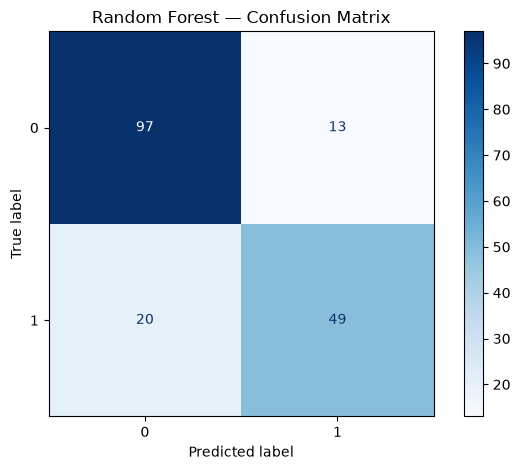

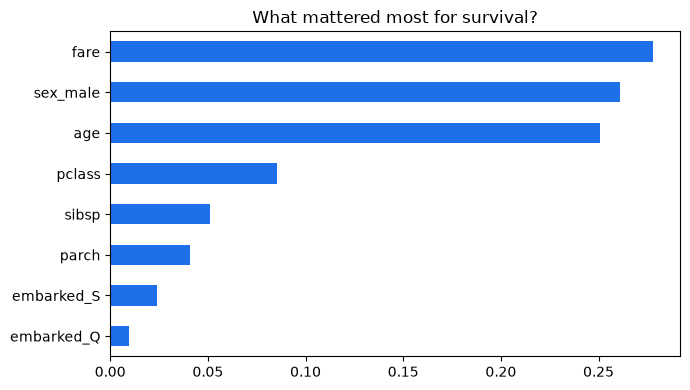

fare          0.277815
sex_male      0.260750
age           0.250883
pclass        0.085506
sibsp         0.050845
parch         0.040757
embarked_S    0.024076
embarked_Q    0.009369
dtype: float64

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay.from_estimator(forest, X_test, y_test, cmap="Blues")
plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

importance = pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=True)
plt.figure(figsize=(7, 4))
importance.plot(kind="barh", color="#1F6FEB")
plt.title("What mattered most for survival?")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()
importance.sort_values(ascending=False)

## What I learned
- Survival was not random: **passenger class, sex and fare** carry most of the signal — women and first-class passengers survived at far higher rates.
- A Random Forest slightly beats plain Logistic Regression here because the relationships are not purely linear.
- Even a simple, well-cleaned dataset can teach the full ML workflow: cleaning → encoding → splitting → training → honest evaluation.